# lab3 — ThaiSLM v9: forward (sign → text) · face emotion · speech

Kernel `490-sign`. Everything below is computed **live** from the shipped models (`models/model-v9`, `models/face-model`,
`models/speech-model-v1`) and the cached front pass of the evaluation sets (`python main.py decision cache`), except the speech
numbers, which need the speech environment and are read from their reports (`python main.py speech …`).
Nothing in this notebook trains or tunes anything — all settings were chosen on **tune** data (`python main.py decision tune`).

| § | what |
|---|---|
| 1 | what changed in v9 (model folders, settings) |
| 2 | TSL51 test 1× / 1.5× / 2× · unseen-signer words · fluent sentences — v8.1 vs v9 (signer-independent) |
| 3 | TSL51 with the signer enrolled (their own word recordings in the bank) — the path to WER ≤ 0.10 |
| 4 | real videos: data_test · iPhone · **team-drive** (raw, per performance, in-vocabulary) — per clip |
| 5 | confidence: accepted precision, coverage, ECE, reliability |
| 6 | streaming: words while signing — latency, flicker, duplicates |
| 7 | face model: held-out actors, sign videos, per-clip affect with explanation |
| 8 | speech: expressive voice + Thai ASR (reports + audio) |
| 9 | production: Docker API vs Python |

In [1]:
import json, sys, time, copy, logging, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)
plt.rcParams["font.family"] = ["Leelawadee UI", "Tahoma", "DejaVu Sans"]
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
from modules.utils import ART, read_json
import decision as D
REP = ART / "reports"
h = D.Harness()
print("harness ready")

harness ready


## 1. What changed in v9

In [2]:
rows = []
for tag in ("v8.1", "v9"):
    b = D.baseline(tag); sp = b["spot"]; cal = b["cal"]
    rows.append(dict(version=tag, reader=sp.get("read", "span head + hand cue"), hand_w=sp.get("hand_w"), grammar_rerank=sp.get("grammar_rerank_weight"),
                     merge_thr=(sp.get("merge") or {}).get("thr"), split_thr=(sp.get("split") or {}).get("thr"), calibration_features=len(cal["model"]["feats"]),
                     isotonic=bool(cal.get("isotonic")), tau_accept=cal["tau_accept"], tau_reject=cal["tau_uncertain"],
                     lone_letter_min=(b["spell"] or {}).get("single_min"), lone_letter_after_name=(b["spell"] or {}).get("single_after_name")))
display(pd.DataFrame(rows).set_index("version").T)
for d in ("model-v9", "face-model", "speech-model-v1"):
    f = ROOT / "models" / d
    print(f"models/{d}: {sum(x.stat().st_size for x in f.rglob('*') if x.is_file()) / 2**20:.0f} MB, {len(list(f.rglob('*')))} files")

version,v8.1,v9
reader,span head + hand cue,"{'crops': 0, 'lm_w': 0.3}"
hand_w,1.2,1.0
grammar_rerank,0.5,0.0
merge_thr,0.4,0.4
split_thr,0.7,0.6
calibration_features,13,16
isotonic,False,True
tau_accept,0.92,0.88
tau_reject,0.15,0.19
lone_letter_min,0.98,0.95


models/model-v9: 684 MB, 30 files
models/face-model: 0 MB, 3 files
models/speech-model-v1: 41 MB, 22 files


## 2. Held-out test sets — v8.1 vs v9 (signer-independent: the bank holds training signers only)

TSL51 test = sentence templates never used for training or tuning, signer not in the bank; 1.5× / 2× = the same videos sped up.
Unseen-signer words = isolated clips of test-role signers; fluent = synthetic fluent sentences of test-role signers.

In [3]:
KEYS = ["WER", "seg_F1", "R1", "R5", "count_err", "acc_prec", "acc_cover", "false_accept_rate"]
res, per = {}, {}
for name in D.TEST_SETS:
    rows = D.load_set(name)
    for tag in ("v8.1", "v9"):
        h.use(tag)
        sc = D.evaluate(h, rows)
        res[(name, tag)] = D.aggregate(sc); per[(name, tag)] = np.array([x["wer"] for x in sc])
T = pd.DataFrame({k: {m: v.get(m) for m in KEYS} for k, v in res.items()}).T.round(3)
display(T)
rng = np.random.RandomState(0); bs = []
for name in D.TEST_SETS:
    d = per[(name, "v9")] - per[(name, "v8.1")]
    b = d[rng.randint(0, len(d), (10000, len(d)))].mean(1)
    bs.append(dict(set=name, dWER=d.mean(), lo=np.percentile(b, 2.5), hi=np.percentile(b, 97.5), better=int((d < 0).sum()), worse=int((d > 0).sum())))
display(Markdown("**Paired bootstrap ΔWER (v9 − v8.1), 10,000 resamples**")); display(pd.DataFrame(bs).round(3))

WER  seg_F1     R1     R5  count_err  acc_prec  acc_cover  false_accept_rate
t51_test_x1.0 v8.1  0.309   0.880  0.700  0.847      0.349     0.980      0.216              0.013
              v9    0.296   0.873  0.720  0.856      0.389     0.973      0.400              0.034
t51_test_x1.5 v8.1  0.284   0.866  0.676  0.804      0.325     0.977      0.278              0.025
              v9    0.263   0.867  0.693  0.809      0.325     0.964      0.420              0.060
t51_test_x2.0 v8.1  0.292   0.818  0.638  0.733      0.524     0.953      0.271              0.056
              v9    0.274   0.823  0.658  0.747      0.492     0.957      0.396              0.078
iso_test      v8.1  0.257   0.943  0.791  0.902      0.093     0.963      0.350              0.045
              v9    0.243   0.943  0.800  0.920      0.093     0.914      0.518              0.169
flu_test      v8.1  0.411   0.933  0.593  0.799      0.408     0.945      0.178              0.029
              v9    0.378   0.928  0.642  0.807      0.433     0.932      0.285              0.062

**Paired bootstrap ΔWER (v9 − v8.1), 10,000 resamples**

,set,dWER,lo,hi,better,worse
0,t51_test_x1.0,-0.013,-0.040,0.013,20,13
1,t51_test_x1.5,-0.021,-0.049,0.007,20,10
2,t51_test_x2.0,-0.018,-0.038,0.002,13,5
3,iso_test,-0.013,-0.044,0.013,7,4
4,flu_test,-0.033,-0.061,-0.004,28,14


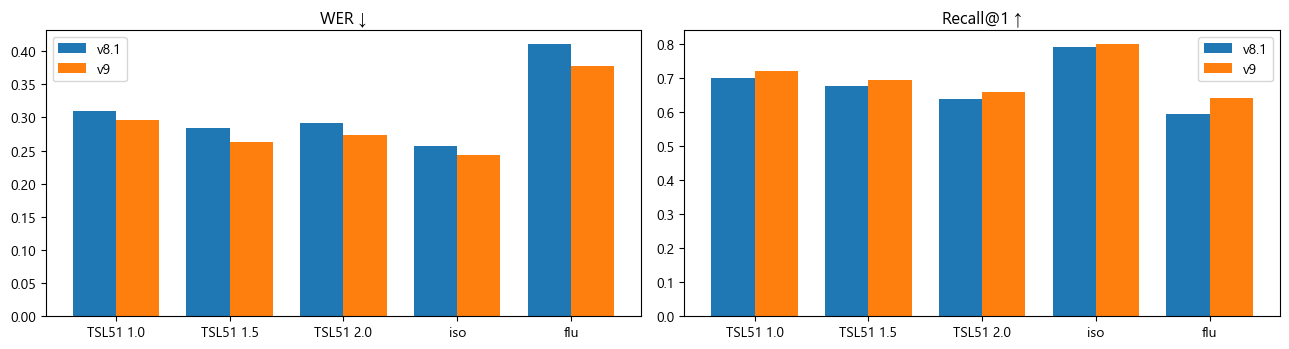

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
names = [n.replace("_test", "").replace("t51_x", "TSL51 ") for n in D.TEST_SETS]
x = np.arange(len(D.TEST_SETS))
for i, tag in enumerate(("v8.1", "v9")):
    ax[0].bar(x + (i - .5) * .38, [res[(n, tag)]["WER"] for n in D.TEST_SETS], .38, label=tag)
    ax[1].bar(x + (i - .5) * .38, [res[(n, tag)]["R1"] for n in D.TEST_SETS], .38, label=tag)
for a, t in zip(ax, ("WER ↓", "Recall@1 ↑")):
    a.set_xticks(x); a.set_xticklabels(names); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

## 3. TSL51 with the signer enrolled

Same test sentences; the bank also holds **the same signer's own isolated word recordings** (`t51u` clips — never the test
sentences). This is what a regular user gets after confirming their signs once in the web app (personal sign memory /
few-shot enrollment). Reported separately: it is a different operating condition, not the signer-independent number above.

In [5]:
eb = D.enrolled_bank(h); keep = h.banks["eval"]
er = {}
for name in ["t51_test_x1.0", "t51_test_x1.5", "t51_test_x2.0"]:
    rows = D.load_set(name)
    for tag in ("v8.1", "v9"):
        h.use(tag); h.banks["eval"] = eb
        er[(name, tag)] = D.aggregate(D.evaluate(h, rows))
        h.banks["eval"] = keep
display(pd.DataFrame({k: {m: v.get(m) for m in KEYS} for k, v in er.items()}).T.round(3))

WER  seg_F1     R1     R5  count_err  acc_prec  acc_cover  false_accept_rate
t51_test_x1.0 v8.1  0.119   0.893  0.840  0.900      0.206     0.950      0.380              0.102
              v9    0.119   0.893  0.840  0.900      0.206     0.950      0.380              0.102
t51_test_x1.5 v8.1  0.109   0.880  0.816  0.862      0.214     0.964      0.411              0.095
              v9    0.109   0.880  0.816  0.862      0.214     0.964      0.411              0.095
t51_test_x2.0 v8.1  0.137   0.845  0.764  0.791      0.333     0.951      0.436              0.143
              v9    0.137   0.845  0.764  0.791      0.333     0.951      0.436              0.143

## 4. Real videos (never used to choose anything): data_test · iPhone · team-drive

`WER` = against the reference as given · `WER per performance` = against the reference repeated as many times as the clip
performs the sentence (Boom's clips sign it 2–3×, separated by hands-down rests; counted automatically, checked by eye) ·
`WER in-vocab` = only the reference words the model knows (an out-of-vocabulary sign can at best be `[?]`) ·
`shown precision` = share of the words shown (Accept + "อาจหมายถึง") that are in the reference.

In [6]:
from modules.decode import wer
real = {}
clip_rows = []
for name in D.REAL_SETS:
    rows = D.load_set(name)
    for tag in ("v8.1", "v9"):
        h.use(tag); h.configure(prior=h.prod_prior)
        sc, segs = D.evaluate(h, rows, keep_segs=True)
        m = D.aggregate(sc)
        reps = [D.performances(D._reload_raw(r)) for r in rows]
        inv = [wer([w for w in r["ref"] if w in h.vocab], x["hyp"]) for r, x in zip(rows, sc) if any(w in h.vocab for w in r["ref"])]
        shown = [c for x in sc for st, c in zip(x["status"], x["correct"]) if st in ("accepted", "uncertain")]
        m.update(WER_per_performance=np.mean([wer(list(r["ref"]) * k, x["hyp"]) for r, x, k in zip(rows, sc, reps)]),
                 WER_in_vocab=np.mean(inv), shown_precision=np.mean(shown) if shown else np.nan)
        real[(name, tag)] = m
        for r, x, ss in zip(rows, sc, segs):
            live = [s for s in ss if s["status"] != "transition"]
            clip_rows.append(dict(set=name, clip=r["id"], version=tag, ref=" ".join(r["ref"]),
                                  hyp=" ".join(s["nearest"] + {"accepted": "", "uncertain": "?"}.get(s["status"], "✗") for s in live), WER=round(x["wer"], 2)))
display(pd.DataFrame({k: {m: v.get(m) for m in ["WER", "WER_per_performance", "WER_in_vocab", "R1", "R5", "count_err", "acc_prec", "shown_precision"]}
                      for k, v in real.items()}).T.round(3))

WER  WER_per_performance  WER_in_vocab     R1     R5  count_err  acc_prec  shown_precision
data_test       v8.1  0.684                0.802         0.674  0.524  0.762      1.000     1.000            0.688
                v9    0.724                0.842         0.724  0.571  0.762      0.800     1.000            0.632
iphone_word     v8.1  0.222                0.222         0.222  1.000  1.000      0.222     1.000            0.818
                v9    0.222                0.222         0.222  1.000  1.000      0.222     1.000            0.818
iphone_sentence v8.1  0.126                0.126         0.233  0.885  0.923      0.200     1.000            0.923
                v9    0.097                0.097         0.233  0.885  0.923      0.000     1.000            0.897
team            v8.1  0.787                0.550         1.444  0.614  0.843      1.667     0.938            0.536
                v9    0.774                0.508         1.435  0.686  0.843      1.722     0.957            0.527

In [7]:
C = pd.DataFrame(clip_rows)
W = C.pivot_table(index=["set", "clip", "ref"], columns="version", values=["hyp", "WER"], aggfunc="first")
display(W)

WER                                                           hyp  \
version                                                                                           v8.1    v9                                                    v8.1   
set             clip                                       ref                                                                                                         
data_test       test1                                      สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ  0.29  0.29               สวัสดี? สบายดี? ชอบ? โกรธ? แมว นั่ง? แมว✗   
                ฉันปลอบเพื่อนร้องไห้                       ฉัน ปลอบใจ เพื่อน ร้องไห้              1.00  1.00                                       เพื่อน ดู✗ สงสาร?   
                ฉันรักเพื่อน                               ฉัน รัก เพื่อน                         0.33  0.33                                               ฉัน? รัก?   
                พ่อดื่มน้ำ                                 พ่อ ดื่ม น้ำ                           1.00  1.00                                 ศูนย์? พ่อ? น้า✗ ศูนย์?   
                ไปทานข้าวด้วยกันมั้ย                       ไป กิน ข้าว ด้วยกัน ไหม                0.80  1.00                                           คุณ? กิน? ไป?   
iphone_sentence sentence/IMG_3302                          สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว          0.14  0.00                     สวัสดี ฉัน? ชื่อ? ถูก✗ ฉัน? ชอบ แมว   
                sentence/IMG_3303                          ฉัน สบายดี คุณ สบายดี                  0.00  0.00                               ฉัน? สบายดี? คุณ? สบายดี?   
                sentence/IMG_3304                          วันนี้ ฉัน นำเสนอ งาน ภาษามือ A I      0.29  0.29                   วันนี้? ฉัน? ห้า? ทำงาน? ภาษามือ? A I   
                sentence/IMG_3305                          วันนี้ ฉัน อยาก เรียน ภาษามือ          0.20  0.20                             วันนี้? ฉัน? เรียน ภาษามือ?   
                sentence/IMG_3307                          พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน      0.00  0.00                 พรุ่งนี้? ฉัน? ไป✗ เที่ยว? ประเทศ? จีน?   
iphone_word     word/IMG_3293                              สวัสดี                                 0.00  0.00                                                 สวัสดี?   
                word/IMG_3295                              สวัสดี                                 0.00  0.00                                                 สวัสดี?   
                word/IMG_3296                              ฉัน                                    0.00  0.00                                                     ฉัน   
                word/IMG_3297                              ชื่อ                                   1.00  1.00                                                ชื่อ? J?   
                word/IMG_3298                              ชอบ                                    0.00  0.00                                                    ชอบ?   
                word/IMG_3299                              แมว                                    0.00  0.00                                                     แมว   
                word/IMG_3308                              พรุ่งนี้                               0.00  0.00                                               พรุ่งนี้?   
                word/IMG_3309                              ไป                                     0.00  0.00                                                     ไป?   
                word/IMG_3311                              จีน                                    1.00  1.00                                           กรุงเทพ? จีน?   
team            Boom/ฉันยังลืมคุณไม่ได้                    ฉัน ยัง ลืม คุณ ไม่ได้                 1.40  1.20                   ยาย? โกรธ? อย่า✗ ชอบ? ญาติ? ไป✗ อย่า✗   
                Boom/ฉันแอบชอบคุณ                          ฉัน แอบ ชอบ คุณ                        1.75  2.00  พ่อ? แต่งงาน? เกิด✗ เป็น✗ แต่งงาน? เกิด? น้องสาว✗ คุณ?   
                Boom/ตอนนี้กำลังเรียนภาษา                  ตอนนี้ ก

## 5. Confidence — is Accept trustworthy, and how much is shown?

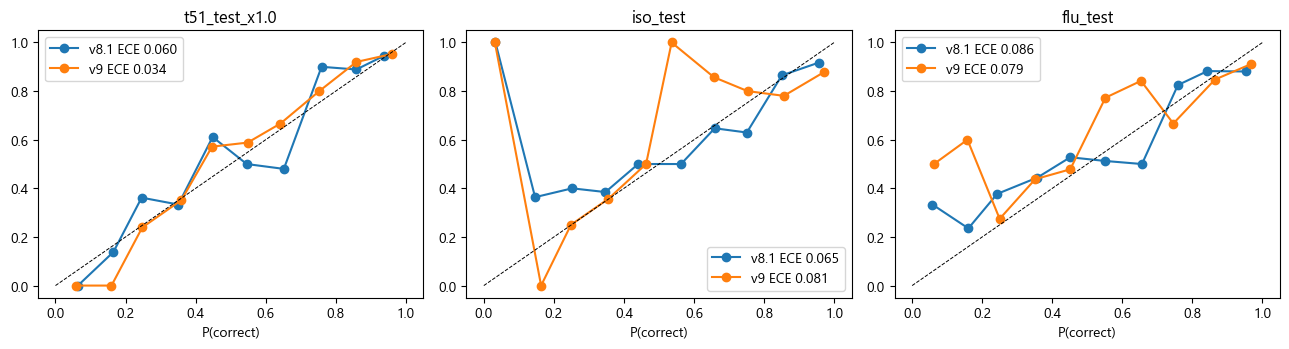

,set,version,ECE,acc_prec,acc_cover,false_accept,correct_not_accepted,correct_rejected
0,t51_test_x1.0,v8.1,0.060,0.980,0.216,0.013,0.692,0.006
1,t51_test_x1.0,v9,0.034,0.973,0.400,0.034,0.444,0.000
2,iso_test,v8.1,0.065,0.963,0.350,0.045,0.556,0.022
3,iso_test,v9,0.081,0.914,0.518,0.169,0.350,0.006
4,flu_test,v8.1,0.086,0.945,0.178,0.029,0.696,0.021
5,flu_test,v9,0.079,0.932,0.285,0.062,0.549,0.036


In [ ]:
from decision import ece, reliability
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
cal_rows = []
for ax, name in zip(axs, ["t51_test_x1.0", "iso_test", "flu_test"]):
    rows = D.load_set(name)
    for tag in ("v8.1", "v9"):
        h.use(tag)
        sc, segs = D.evaluate(h, rows, keep_segs=True)
        P = np.array([s.get("p_correct", 0) for ss in segs for s in ss if s["status"] != "transition"]); Y = np.array([c for x in sc for c in x["correct"]], float)
        rel = [r for r in reliability(P, Y) if r["n"] > 0]
        ax.plot([r["conf"] for r in rel], [r["acc"] for r in rel], "o-", label=f"{tag} ECE {ece(P, Y):.3f}")
        m = D.aggregate(sc)
        cal_rows.append(dict(set=name, version=tag, ECE=ece(P, Y), acc_prec=m["acc_prec"], acc_cover=m["acc_cover"], false_accept=m["false_accept_rate"],
                             correct_not_accepted=m["correct_not_accepted"], correct_rejected=m["correct_rejected"]))
    ax.plot([0, 1], [0, 1], "k--", lw=.7); ax.set_title(name); ax.set_xlabel("P(correct)"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(cal_rows).round(3))

## 6. Streaming — words while signing (`modules/stream.py`)

Each real video is replayed **in stream time**: frames arrive at their timestamps, the pipeline runs every 0.5 s on a bounded
window, and a step can only start when the previous one finished (compute counted). Latency = when a word is confirmed −
when that sign ended. MediaPipe (≈ 28 ms / frame on this CPU, in the browser on the web) is not included.

In [9]:
from modules.pipeline import SignPipeline
from modules.mediapipe_pose import load_raw
from modules.stream import replay
pipe9 = SignPipeline(model_dir=ROOT / "models" / "model-v9", use_llm=False, use_face=False)
srow, lat, proc = [], [], []
for name in ("iphone_sentence", "data_test", "team"):
    for r in D.load_set(name):
        raw = D._reload_raw(r)
        batch = [s["nearest"] for s in pipe9.run_landmarks(raw)["segments"] if s["status"] != "transition"]
        words, st = replay(pipe9, raw)
        lat += st["latency"]; proc += st["proc_ms"]
        srow.append(dict(set=name, clip=r["id"], ref=" ".join(r["ref"]), batch=" ".join(batch), stream=" ".join(words), WER_stream=round(wer(r["ref"], words), 2),
                         WER_batch=round(wer(r["ref"], batch), 2), flicker=st["flicker"], duplicates=st["duplicates"]))
S = pd.DataFrame(srow); display(S)
print(f"word latency p50 {np.percentile(lat, 50):.2f} s · p95 {np.percentile(lat, 95):.2f} s | step compute p50 {np.percentile(proc, 50):.0f} ms · p95 {np.percentile(proc, 95):.0f} ms"
      f" | stream WER {S.WER_stream.mean():.3f} vs batch {S.WER_batch.mean():.3f} | duplicates {S.duplicates.sum()} · flicker/clip {S.flicker.mean():.1f}")

,set,clip,ref,batch,stream,WER_stream,WER_batch,flicker,duplicates
0,iphone_sentence,sentence/IMG_3302,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,0.00,0.00,1,0
1,iphone_sentence,sentence/IMG_3303,ฉัน สบายดี คุณ สบายดี,ฉัน สบายดี คุณ สบายดี,ฉัน สบายดี คุณ สบายดี,0.00,0.00,1,0
2,iphone_sentence,sentence/IMG_3304,วันนี้ ฉัน นำเสนอ งาน ภาษามือ A I,วันนี้ ฉัน ห้า ทำงาน ภาษามือ A I,วันนี้ ฉัน ห้า ทำงาน ภาษามือ A I,0.29,0.29,3,0
3,iphone_sentence,sentence/IMG_3305,วันนี้ ฉัน อยาก เรียน ภาษามือ,วันนี้ ฉัน ชอบ เรียน ภาษามือ,วันนี้ ฉัน เรียน ภาษามือ,0.20,0.20,1,0
4,iphone_sentence,sentence/IMG_3307,พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน,พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน,พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน,0.00,0.00,4,0
5,data_test,test1,สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ,สวัสดี สบายดี ชอบ โกรธ แมว ปิด แมว,สวัสดี สบายดี ชอบ โกรธ แมว ปิด แมว,0.29,0.29,7,0
6,data_test,ฉันปลอบเพื่อนร้องไห้,ฉัน ปลอบใจ เพื่อน ร้องไห้,เพื่อน ดู สงสาร,เพื่อน ดู ข้าว สงสาร,1.00,1.00,6,0
7,data_test,ฉันรักเพื่อน,ฉัน รัก เพื่อน,ฉัน รัก,ฉัน รัก,0.33,0.33,2,0
8,data_test,พ่อดื่มน้ำ,พ่อ ดื่ม น้ำ,ศูนย์ พ่อ น้ำ ศูนย์,ศูนย์ พ่อ น้ำ ดื่ม,1.00,1.00,10,0
9,data_test,ไปทานข้าวด้วยกันมั้ย,ไป กิน ข้าว ด้วยกัน ไหม,คุณ ฉัน กิน ไป,หนึ่ง คุณ ด้วยกัน กิน ไป,1.00,1.00,6,0


word latency p50 1.53 s · p95 2.40 s | step compute p50 304 ms · p95 486 ms | stream WER 0.610 vs batch 0.645 | duplicates 0 · flicker/clip 4.9


## 7. Face model (`models/face-model`) — what the signer feels, and why

Trained on RAVDESS (24 actors, acted emotions) through the same MediaPipe extractor; evaluated on actors the model never saw.
Then on sign videos (no emotion labels exist): neutral dictionary signing should stay neutral; dictionary signs of emotion words
are usually made with a matching face. Then the fused affect (face + recognised words + signing energy) of real clips.

,held-out actors
l2,0.010000
temperature,1.600000
clips_acc,0.563889
clips_macro_f1,0.567380
windows_acc,0.552484
windows_macro_f1,0.554123
strong_intensity_acc,0.630952
neutral_vs_emotion_acc,0.812500
valence_sign_agreement,0.685417
chance,0.200000


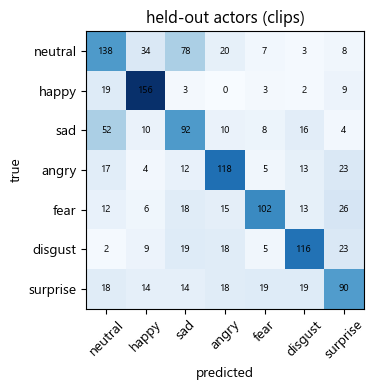

,sign videos
neutral_clips,299.000000
emotion_word_clips,52.000000
false_alarm_model,0.123746
false_alarm_rule,0.260870
emotion_words_valence_agree_model,0.307692
emotion_words_valence_agree_rule,0.269231
emotion_words_nonneutral_model,0.365385
emotion_words_nonneutral_rule,0.365385
emotion_words_exact_model,0.134615
emotion_words_exact_rule,0.115385


In [10]:
card = read_json(ROOT / "models/face-model/model_card.json"); cv = card["cv"]
display(pd.Series({k: v for k, v in cv.items() if k not in ("confusion",)}).to_frame("held-out actors"))
M = np.array(cv["confusion"]["matrix"]); lab = cv["confusion"]["labels"]
fig, ax = plt.subplots(figsize=(4.6, 4)); ax.imshow(M / M.sum(1, keepdims=True), cmap="Blues")
ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45); ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
for i in range(len(lab)):
    for j in range(len(lab)):
        ax.text(j, i, M[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("held-out actors (clips)"); plt.tight_layout(); plt.show()
sg = read_json(REP / "face_model_signs.json")
display(pd.Series({k: v for k, v in sg.items() if k != "per_clip"}).to_frame("sign videos"))

In [11]:
pipe_f = SignPipeline(model_dir=ROOT / "models" / "model-v9", use_llm=False, use_face=True)
fr = []
for name in ("team", "data_test", "iphone_sentence"):
    for r in D.load_set(name):
        out = pipe_f.run_landmarks(D._reload_raw(r))
        a = out["face"].get("affect", {})
        fr.append(dict(set=name, clip=r["id"], words=" ".join(s["nearest"] for s in out["segments"] if s["status"] in ("accepted", "uncertain")),
                       emotion=a.get("emotion"), intensity=a.get("intensity"), valence=a.get("valence"), arousal=a.get("arousal"),
                       rule_v7=out["face"].get("rule_emotion"), explanation=a.get("explanation_th")))
display(pd.DataFrame(fr))

,set,clip,words,emotion,intensity,valence,arousal,rule_v7,explanation
0,team,Pitty/พรุ่งนี้ฉันไปโรงเรียน,แฟน พรุ่งนี้ ฉัน โรงเรียน น้อง,neutral,0.000,0.060,0.377,happy,สีหน้าเป็นกลาง (ความมั่นใจ 80%) ; ท่ามือเร็ว/แรง
1,team,Pitty/สวัสดีฉันชื่อ P,สวัสดี ฉัน ชื่อ P,neutral,0.000,-0.135,0.297,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 74%) ; ท่ามือเร็ว/แรง
2,team,Pitty/ฉันคิดถึงแม่,ฉัน แม่,neutral,0.000,-0.068,0.297,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 82%) ; ท่ามือเร็ว/แรง
3,team,Pitty/ฉันชอบกินขนมปัง,ฉัน กิน ขนมปัง,neutral,0.000,-0.023,0.313,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 76%) ; ท่ามือเร็ว/แรง
4,team,Pitty/พรุ่งนี้ฉันไปเที่ยว,พรุ่งนี้ เที่ยว ที่ไหน,neutral,0.000,-0.072,0.221,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 79%) ; ท่ามือเร็ว/แรง
5,team,Pitty/ฉันรักเพื่อน,ฉัน เพื่อน,neutral,0.000,-0.263,0.049,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 52%)
6,team,Pitty/วันหยุดพ่อชอบไปตลาด,วัน เที่ยว ชอบ เพื่อน แม่ ตลาด,neutral,0.000,-0.309,0.482,neutral,สีหน้าเป็นกลาง (ความมั่นใจ 40%) ; ท่ามือเร็ว/แรง
7,team,Boom/ฉันยังลืมคุณไม่ได้,แฟน ทำไม ชอบ ญาติ,surprise,0.717,0.003,0.782,surprise,สีหน้าประหลาดใจ / ตกใจ (ความมั่นใจ 56%) เพราะหางคิ้วขวายก · ขยับคาง ; ท่ามือเร็ว/แรง
8,team,Boom/ฉันแอบชอบคุณ,สิบ จีน ที่ไหน แต่งงาน ฉัน เที่ยว,neutral,0.000,-0.145,0.338,surprise,สีหน้าเป็นกลาง (ความมั่นใจ 65%) ; ท่ามือเร็ว/แรง
9,team,Boom/ตอนนี้กำลังเรียนภาษา,วันนี้ เรียน กรุงเทพ โสด วันนี้ เรียน โสด,surprise,0.844,0.036,0.845,surprise,สีหน้าประหลาดใจ / ตกใจ (ความมั่นใจ 64%) เพราะหางคิ้วขวายก ; ส่ายหน้า = ปฏิเสธ (ไวยากรณ์) ; ท่ามือเร็ว/แรง


## 8. Speech (`models/speech-model-v1`) — a natural voice that carries the emotion, and an ear for the hearing partner

Run in the speech environment (`D:/SLM-labs/envs/speech`): `python main.py speech tts-eval | asr-eval [--lora] | demo`.

In [12]:
tts = read_json(REP / "speech_tts_v1.json")
display(pd.Series(dict(v1_CER=tts["v1"]["CER"], old_MMS_CER=tts["old_mms"]["CER"], rtf_gpu=tts["v1"]["rtf_gpu"], rtf_cpu=tts["v1"]["rtf_cpu"],
                       **{f"prosody shift follows reference ({k})": v for k, v in tts["shift_follows_reference_corr"].items()})).to_frame("voice v1"))
display(pd.DataFrame(tts["emotion_shift"]).round(2))
asr = {k: read_json(REP / f"speech_asr_{k}.json") for k in ("base", "lora") if (REP / f"speech_asr_{k}.json").exists()}
display(pd.DataFrame({k: {s: v[s]["CER"] for s in v} for k, v in asr.items()}).round(4).rename(columns={"base": "Qwen3-ASR-0.6B", "lora": "+ LoRA (v1)"}))

,voice v1
v1_CER,0.000595
old_MMS_CER,0.082148
rtf_gpu,1.538656
rtf_cpu,293.468865
prosody shift follows reference (f0_st),0.776616
prosody shift follows reference (f0_range_st),-0.007506
prosody shift follows reference (loud_db),0.221782


,voice,emotion,CER,rtf,d_f0_st,ref_d_f0_st,d_f0_range_st,ref_d_f0_range_st,d_loud_db,ref_d_loud_db,d_rate
0,female,angry,0.00,1.55,3.07,3.00,3.77,-0.89,-0.06,2.00,0.0
1,female,disgust,0.00,1.53,2.41,2.70,3.89,-0.76,0.22,0.23,0.0
2,female,fear,0.00,1.51,1.70,1.10,-0.65,-1.38,-1.33,-0.45,0.0
3,female,happy,0.00,1.56,0.69,3.25,1.19,-2.46,-0.70,-1.18,0.0
4,female,neutral,0.01,1.63,0.00,0.00,0.00,0.00,0.00,0.00,0.0
5,female,sad,0.00,1.52,-0.62,0.20,4.47,-1.58,-0.17,-0.77,0.0
6,female,surprise,0.00,1.50,4.41,4.80,1.06,-2.31,-0.92,0.88,0.0
7,male,angry,0.00,1.53,3.63,4.75,3.40,-2.99,1.11,2.04,0.0
8,male,disgust,0.00,1.58,1.74,1.90,2.82,1.19,-0.37,-0.16,0.0
9,male,fear,0.00,1.54,6.68,5.25,4.61,-5.09,-0.62,1.12,0.0


,Qwen3-ASR-0.6B,+ LoRA (v1)
asr_th (short daily phrases),0.2149,0.2136
"test-A (held-out sentences, male voice)",0.0201,0.0178
FLEURS-th (real read speech),0.0667,0.0842
held-out synthetic conversation,0.0420,0.0129


In [13]:
sdir = ROOT / "result_reporting" / "speech_samples_v1"
demo = read_json(sdir / "demo.json")
for d in demo:
    display(Markdown(f"**{d['clip']}** — signs: {' '.join(w for w, s, p in d['words'])} → says: *{d['said']}* · {d['emotion']} ({d['intensity']}) · speed {d['speed']}  \n{d['affect_explanation']}"))
    f = sdir / f"demo_{d['clip']}.wav"
    if f.exists():
        display(Audio(str(f)))
for e in ("neutral", "happy", "sad", "angry"):
    display(Markdown(f"voice v1, female, **{e}**")); display(Audio(str(sdir / f"female_{e}.wav")))
display(Markdown("old voice (MMS-TTS)")); display(Audio(str(sdir / "old_mms_neutral.wav")))

**iphone_3307** — signs: พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน → says: *พรุ่งนี้ ฉัน จีน* · neutral (0.0) · speed 1.019  
สีหน้าเป็นกลาง (ความมั่นใจ 80%) ; ท่ามือเร็ว/แรง

**iphone_3302** — signs: สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว → says: *สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว* · neutral (0.0) · speed 1.018  
สีหน้าเป็นกลาง (ความมั่นใจ 68%) ; ท่ามือเร็ว/แรง

**data_test_รักเพื่อน** — signs: ฉัน รัก → says: *ฉัน รัก* · happy (0.78) · speed 1.067  
สีหน้าดีใจ / มีความสุข (ความมั่นใจ 59%) เพราะมุมปากขวายก (ยิ้ม) · มุมปากซ้ายยก (ยิ้ม) · ยกริมฝีปากบน ; คำที่ทำ: 'รัก' (ดีใจ)

**team_pitty_คิดถึงแม่** — signs: ฉัน แม่ → says: *ฉัน แม่* · neutral (0.0) · speed 1.015  
สีหน้าเป็นกลาง (ความมั่นใจ 82%) ; ท่ามือเร็ว/แรง

**team_boom_แอบชอบ** — signs: สิบ จีน เกิด ที่ไหน แต่งงาน ฉัน เที่ยว เป็น → says: ** · neutral (0.0) · speed 1.017  
สีหน้าเป็นกลาง (ความมั่นใจ 65%) ; ท่ามือเร็ว/แรง

voice v1, female, **neutral**

voice v1, female, **happy**

voice v1, female, **sad**

voice v1, female, **angry**

old voice (MMS-TTS)

## 9. Production — Docker (`docker compose up --build`) vs Python

The API container (`sign-api`, ONNX Runtime, no PyTorch) serves `models/model-v9` + `models/face-model`. The same team-drive
video is sent to the running API and translated in Python here; the words must match.

In [14]:
import requests
vid = ROOT / "data_test/team-drive/Eval-Test/Jack/พรุ่งนี้ผมจะไปเที่ยวประเทศจีน.MOV"
try:
    t = time.time()
    with open(vid, "rb") as f:
        r = requests.post("http://localhost:8080/api/v1/translate/video", files={"file": (vid.name, f, "video/quicktime")},
                          params=dict(llm="false"), timeout=600).json()
    api_words = [s["word"] for s in r["segments"] if s["status"] != "transition"]
    print(f"API ({time.time() - t:.1f} s incl. MediaPipe): {api_words}")
    print("model:", r.get("model"), "| face:", (r.get("face") or {}).get("affect", {}).get("explanation_th"))
    py = SignPipeline(model_dir=ROOT / "models" / "model-v9", use_llm=False, use_face=True).run(str(vid))
    py_words = [s["nearest"] for s in py["segments"] if s["status"] != "transition"]
    print("Python:", py_words, "| identical:", api_words == py_words)
except requests.ConnectionError:
    print("API not running — start it with: docker compose up --build")

API (16.0 s incl. MediaPipe): ['พรุ่งนี้', 'ฉัน', 'ไป', 'เที่ยว', 'ประเทศ', 'จีน']
model: v9 | face: สีหน้าเป็นกลาง (ความมั่นใจ 85%) ; ท่ามือเร็ว/แรง


Python: ['พรุ่งนี้', 'ฉัน', 'ไป', 'เที่ยว', 'ประเทศ', 'จีน'] | identical: True
